# WattRota — Model geliştirme ve karar doğrulaması

## 1. Amaç ve deney ayrımı

İlk fiyat modelinin bilgi kullanımını geliştirmek, fiyat hatası ile üretim kararının maliyetini ayrı ölçmek ve MILP arama süresinin etkisini ayırmak amaçlanır. Eski çalışmalar değiştirilmeden karşılaştırma kaynağı olarak korunur.

Yeni fiyat modelleri 2025'in ilk yarısındaki 26 haftalık kararın MAE'siyle seçilir. Seçim sabitlendikten sonra ikinci yarıdaki 26 karar ve 2026'daki 44 karar değerlendirilir. 2026 daha önce görülmüş bir dönemdir; yeniden yapılan bu karşılaştırma yeni kör test sayılmaz. Özellikler ve eğitim her kararın bilgi sınırına uyar.

Üç deney ayrı yorumlanır: saatlik fiyat tahmini, aynı 19 geçerli seçenek arasında tam taramayla plan seçimi ve ana MILP motorundaki süre sınırlı kontrol.

In [1]:
from pathlib import Path
import sys
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

proje = Path.cwd()
if not (proje / "src").is_dir():
    proje = proje.parent
sys.path.insert(0, str(proje / "src"))
from fiyat_tahmini import elektrik_fiyatlarini_oku, hata_ozeti
from firma_cizelgeleme import firma_verisini_oku, maliyet_ve_ozet
from ortak_plan_karsilastirmasi import arsivden_plan, tarihleri_tasi

folder = proje / "data/results/tahmin_gelistirme"
havuz = proje / "data/results/ortak_plan_deneyi"
izler = json.loads((folder / "deney_izleri.json").read_text(encoding="utf-8"))
for ad, beklenen in izler.items():
    assert hashlib.sha256((proje / ad).read_bytes()).hexdigest() == beklenen, ad
secim = json.loads((folder / "secilen_model.json").read_text(encoding="utf-8"))
secilen = secim["model"]
tahminler = pd.read_csv(folder / "saatlik_tahminler.csv", parse_dates=["karar_zamani", "tarih_saat"])
ozet = hata_ozeti(tahminler)
pd.testing.assert_frame_equal(ozet, pd.read_csv(folder / "hata_ozeti.csv"), check_dtype=False)
protokol = json.loads((folder / "protokol.json").read_text(encoding="utf-8"))
secim_tablosu = ozet[(ozet["bolum"] == "gelistirme_2025_ilk_yari") & ozet["model"].isin(protokol["adaylar"])]
assert secilen == secim_tablosu.sort_values(["MAE_TL_MWh", "model"]).iloc[0]["model"]
etiket = {"son_yayinlanan_gun": "Basit yöntem", "random_forest_365gun": "İlk ML",
          secilen: "Geliştirilmiş fiyat ML"}

## 2. Bilgi kullanımının geliştirilmesi

İlk modelde en yeni fiyat özelliği t−48 idi. Bu düzen gelecek sızıntısını önlüyor, ancak ikinci gün tahmininde açıklanmış ilk gün profilini tam kullanmıyordu. Yeni örnekler karar zamanı, hedef saat ve hedef günle tanımlanır. Model iki hedef gün için de açıklanmış günün aynı saatini, günlük özetini, geçmiş hafta profillerini ve değişimleri kullanır.

Öğrenme hedefi doğrudan fiyat yerine **açıklanmış gün profilinden sapma** olarak kurulur. Tahmin bu profile öğrenilen düzeltmenin eklenmesiyle elde edilir. Random Forest ve iki eğitim penceresiyle gradient boosting karşılaştırılır. Sabit adaylar ve seçim dönemleri protokol dosyasındadır; 2026'ya göre parametre seçilmez.

In [2]:
print("Seçilen fiyat modeli:", secilen)
print("Seçim dönemi:", "2025 Ocak–Haziran")
ozet.round(2)

Seçilen fiyat modeli: hgb_duzeltme_365
Seçim dönemi: 2025 Ocak–Haziran
Out[2]: 
                       bolum  ...  ortalama_isaretli_hata
0   gelistirme_2025_ilk_yari  ...                  -25.38
1   gelistirme_2025_ilk_yari  ...                   15.07
2   gelistirme_2025_ilk_yari  ...                   44.50
3      onay_2025_ikinci_yari  ...                   35.67
4          geriye_donuk_2026  ...                   37.34
5   gelistirme_2025_ilk_yari  ...                  -35.97
6   gelistirme_2025_ilk_yari  ...                  -74.25
7      onay_2025_ikinci_yari  ...                  -39.46
8      onay_2025_ikinci_yari  ...                  -80.23
9          geriye_donuk_2026  ...                 -123.70
10         geriye_donuk_2026  ...                 -105.00

[11 rows x 7 columns]


Basit yönteme göre MAE azalması: %17.02
İlk ML'ye göre MAE azalması: %12.66


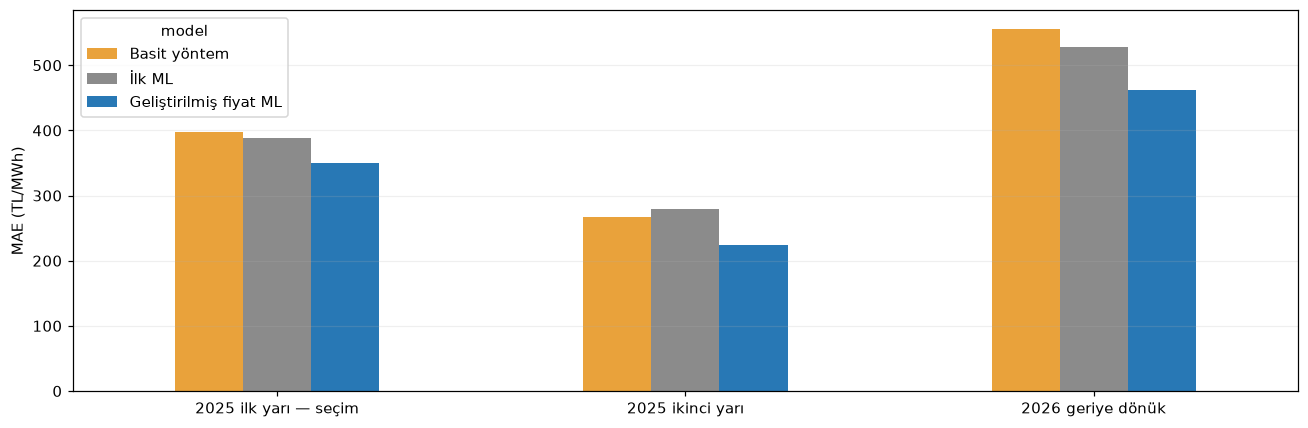

In [3]:
secili = ozet[ozet["model"].isin(etiket)].copy()
grafik = secili.pivot(index="bolum", columns="model", values="MAE_TL_MWh")
sira = ["gelistirme_2025_ilk_yari", "onay_2025_ikinci_yari", "geriye_donuk_2026"]
grafik = grafik.reindex(sira)[list(etiket)]
gosterim = grafik.rename(columns=etiket, index={sira[0]: "2025 ilk yarı — seçim",
    sira[1]: "2025 ikinci yarı", sira[2]: "2026 geriye dönük"})
ax = gosterim.plot.bar(figsize=(12, 4), rot=0, color=["#e9a23b", "#8b8b8b", "#2878b5"])
ax.set_ylabel("MAE (TL/MWh)")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

ileri = ozet[ozet["bolum"] == "geriye_donuk_2026"].set_index("model")
print(f"Basit yönteme göre MAE azalması: %{100*(1-ileri.loc[secilen,'MAE_TL_MWh']/ileri.loc['son_yayinlanan_gun','MAE_TL_MWh']):.2f}")
print(f"İlk ML'ye göre MAE azalması: %{100*(1-ileri.loc[secilen,'MAE_TL_MWh']/ileri.loc['random_forest_365gun','MAE_TL_MWh']):.2f}")

## 3. Ucuz saatleri ayırt etme

Her hedef günde tahmine göre en ucuz altı saatin gerçek ortalama fiyatı ile gerçekte en ucuz altı saatin ortalaması arasındaki fark hesaplanır. Düşük fark daha iyi saat sıralaması anlamına gelir. Bu bir fiyat tanısıdır; fabrika maliyeti veya uygulanabilir altı saatlik bir üretim işi değildir.

In [4]:
saat_hatasi = pd.read_csv(folder / "saat_secimi_hatalari.csv")
saat_hatasi.groupby(["bolum", "model"])["ucuz_saat_fiyat_farki_TL_MWh"].mean().unstack().round(2)

Out[4]: 
model                     hgb_duzeltme_180  ...  son_yayinlanan_gun
bolum                                       ...                    
gelistirme_2025_ilk_yari            151.34  ...              199.59
geriye_donuk_2026                      NaN  ...              211.29
onay_2025_ikinci_yari                  NaN  ...              204.46

[3 rows x 5 columns]


## 4. Aynı seçenekler arasında karar karşılaştırması

Yalnızca 2025 referans ve öneri planlarından, kaynak/yükleme bileşimleri oluşturuldu. Bütün tesis kontrollerinden geçen 19 farklı seçenek saklandı. 2026 gerçek fiyatlarıyla oluşturulmuş planlar havuza alınmadı.

Her yönteme aynı 19 seçenek verilir. Beklenen maliyetlerin tamamı hesaplandığından bu deneyde arama süresi etkisi yoktur. Gerçek fiyatlarla da havuz minimumu tam hesaplanır. Bu minimum, **yalnızca bu seçenek kümesinin minimumudur**; fabrikanın bütün çizelgelerinin global optimumu değildir. Ana MILP motoru bu deneyden ayrı çalışır.

In [5]:
indeks = pd.read_csv(havuz / "plan_indeksi.csv")
enerji = np.load(havuz / "saatlik_enerji.npy")
np.testing.assert_allclose(enerji, pd.read_csv(havuz / "saatlik_enerji.csv", index_col=0).to_numpy())
temel = firma_verisini_oku(proje)
for i, r in indeks.iterrows():
    p, y = arsivden_plan(havuz, r["plan_id"], pd.Timestamp("2025-10-06"), pd.Timestamp("2025-10-06"))
    o = maliyet_ve_ozet(temel, p, y)[-1]
    hesap = enerji[i] @ temel["fiyatlar"]["PTF (TL/MWh)"].to_numpy()/1000 + r["elektrik_disi_gider_tl"]
    assert np.isclose(o.iloc[-1], hesap, atol=0.02, rtol=0)
print(len(indeks), "planın fiziksel koşulları ve enerji-maliyet hesabı doğrulandı.")

kararlar = pd.read_csv(havuz / "haftalik_kararlar.csv", parse_dates=["karar_zamani"])
assert kararlar["bagimsiz_kontrol"].all()
assert (kararlar["havuz_minimumuna_fark_tl"] >= -0.02).all()
assert kararlar["karar_zamani"].nunique() == 44
pd.read_csv(havuz / "ortak_plan_ozeti.csv").round(2)

19 planın fiziksel koşulları ve enerji-maliyet hesabı doğrulandı.
Out[5]: 
                  model  ...  ortalama_avantaj_tl
0      hgb_duzeltme_365  ...              2567.30
1  random_forest_365gun  ...              2832.27
2    son_yayinlanan_gun  ...              2833.61

[3 rows x 5 columns]


In [6]:
eslesme = kararlar.pivot(index="karar_zamani", columns="model", values="gercek_maliyet_tl")
fark = eslesme["son_yayinlanan_gun"] - eslesme[secilen]
print("Yeni fiyat ML daha ucuz:", int((fark > 0.02).sum()), "hafta")
print("Aynı maliyet:", int((fark.abs() <= 0.02).sum()), "hafta")
print("Yeni fiyat ML daha pahalı:", int((fark < -0.02).sum()), "hafta")
print(f"Basit yönteme göre ortalama avantaj: {fark.mean():.2f} TL (negatif: daha pahalı)")

Yeni fiyat ML daha ucuz: 1 hafta
Aynı maliyet: 40 hafta
Yeni fiyat ML daha pahalı: 3 hafta
Basit yönteme göre ortalama avantaj: -266.31 TL (negatif: daha pahalı)


## 5. Karar maliyetiyle tahminleri birleştirme

Basit yöntem ile geliştirilmiş fiyat ML'nin beş birleşim oranı, yalnız 2025'in tamamındaki karar maliyetiyle karşılaştırıldı. 2026 sonuçları hesaplanmadan oran kaydedildi. Bu oran için 2025 ikinci yarı da kalibrasyon verisidir. Oranın geçmiş yılda iyi olması sonraki döneme üstünlük garantisi vermez.

In [7]:
kalibrasyon = json.loads((folder / "karar_kalibrasyonu.json").read_text(encoding="utf-8"))
print("2025 maliyetiyle seçilen ML katkısı:", kalibrasyon["ml_orani"])
kalibrasyon_kayitlari = pd.read_csv(folder / "karar_kalibrasyon_kayitlari.csv", parse_dates=["karar_zamani"])
assert kalibrasyon_kayitlari["karar_zamani"].dt.year.eq(2025).all()
secilen_oran = kalibrasyon_kayitlari.groupby("ml_orani", as_index=False)["gercek_maliyet_tl"].mean().sort_values(["gercek_maliyet_tl", "ml_orani"]).iloc[0]["ml_orani"]
assert kalibrasyon["ml_orani"] == secilen_oran
pd.read_csv(folder / "karar_kalibrasyon_ozeti.csv").round(2)

2025 maliyetiyle seçilen ML katkısı: 1.0
Out[7]: 
   ml_orani  gercek_maliyet_tl
0      1.00          618340.97
1      0.50          618350.97
2      0.75          618372.16
3      0.00          618422.98
4      0.25          618433.94


## 6. Maliyet farkını doğrudan öğrenme

Ek model saatlik fiyat üretmek yerine planların referansa göre maliyet farkında basit tahminin yanılmasını öğrenir. Aynı 19 seçeneğe özgüdür. Ridge ve çok çıktılı Random Forest ile üç katkı oranı 2025 ilk yarı maliyetinden seçilir. Daha sonraki dönemlerde seçim değiştirilmez. Böylece fiyat MAE'sini azaltmak ile karar maliyetini öğrenmek ayrı sınanır.

In [8]:
maliyet_secimi = json.loads((folder / "maliyet_modeli_secimi.json").read_text(encoding="utf-8"))
print(maliyet_secimi)
pd.read_csv(folder / "maliyet_modeli_ozeti.csv").round(2)

{'model': 'rf_maliyet', 'katki': 1.0, 'secim_donemi': '2025 Ocak–Haziran', 'amac': 'Aynı 19 plan içinde maliyet düzeltmesi; saatlik fiyat tahmini değildir.'}
Out[8]: 
                       bolum  ...  ortalama_havuz_farki_tl
0   gelistirme_2025_ilk_yari  ...                   810.44
1   gelistirme_2025_ilk_yari  ...                   626.97
2   gelistirme_2025_ilk_yari  ...                   466.19
3   gelistirme_2025_ilk_yari  ...                   810.44
4   gelistirme_2025_ilk_yari  ...                   701.07
5   gelistirme_2025_ilk_yari  ...                   667.36
6   gelistirme_2025_ilk_yari  ...                   810.44
7   gelistirme_2025_ilk_yari  ...                   690.47
8   gelistirme_2025_ilk_yari  ...                   548.58
9          geriye_donuk_2026  ...                   855.18
10     onay_2025_ikinci_yari  ...                   312.75

[11 rows x 6 columns]


Maliyet modelinin 44 seçimi bağımsız tesis hesabından geçti.


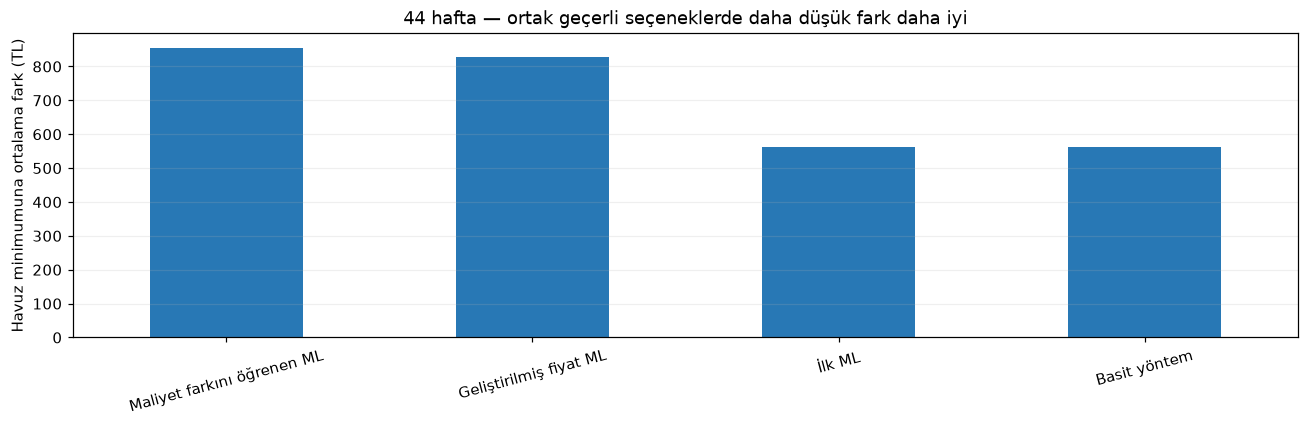

In [9]:
maliyet_kararlari = pd.read_csv(folder / "maliyet_modeli_kararlari.csv", parse_dates=["karar_zamani", "egitim_son_karar"])
ilk_yari = maliyet_kararlari[maliyet_kararlari["bolum"] == "gelistirme_2025_ilk_yari"]
karar_secimi = ilk_yari.groupby(["model", "katki"], as_index=False)["gercek_maliyet_tl"].mean().sort_values(["gercek_maliyet_tl", "katki", "model"]).iloc[0]
assert maliyet_secimi["model"] == karar_secimi["model"]
assert maliyet_secimi["katki"] == karar_secimi["katki"]
maliyet_ileri = maliyet_kararlari[maliyet_kararlari["bolum"] == "geriye_donuk_2026"].copy()
assert (maliyet_ileri["egitim_son_karar"] + pd.Timedelta(hours=72)
        <= maliyet_ileri["karar_zamani"] + pd.Timedelta(hours=24)).all()
ham = elektrik_fiyatlarini_oku(proje)
for r in maliyet_ileri.itertuples(index=False):
    v = tarihleri_tasi(temel, r.karar_zamani)
    s = v["tesis_takvimi"]["tarih_saat"]
    v["fiyatlar"] = pd.DataFrame({"tarih_saat": s, "PTF (TL/MWh)": ham.reindex(s).to_numpy()})
    p, y = arsivden_plan(havuz, r.secilen_plan, r.karar_zamani, pd.Timestamp("2025-10-06"))
    o = maliyet_ve_ozet(v, p, y)[-1]
    assert np.isclose(o.iloc[-1], r.gercek_maliyet_tl, atol=0.02, rtol=0)
print("Maliyet modelinin 44 seçimi bağımsız tesis hesabından geçti.")
birlesik = kararlar.loc[kararlar["model"].isin(etiket),
    ["karar_zamani", "model", "gercek_maliyet_tl", "havuz_minimumuna_fark_tl"]].copy()
ek = maliyet_ileri[["karar_zamani", "gercek_maliyet_tl", "havuz_minimumuna_fark_tl"]].copy()
ek["model"] = "dogrudan_maliyet_ml"
birlesik = pd.concat([birlesik, ek], ignore_index=True)
g = birlesik.groupby("model")["havuz_minimumuna_fark_tl"].mean()
adlar = dict(etiket, dogrudan_maliyet_ml="Maliyet farkını öğrenen ML")
ax = g.rename(index=adlar).plot.bar(figsize=(12, 4), rot=15, color="#2878b5")
ax.set_ylabel("Havuz minimumuna ortalama fark (TL)")
ax.set_xlabel("")
ax.set_title("44 hafta — ortak geçerli seçeneklerde daha düşük fark daha iyi")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 7. Ana çizelgeleme motorunda eşit bütçeli kontrol

5 Ekim 2026 örneğinde her yöntem ortak havuzdan kendi tahminine göre seçtiği planla başlatıldı. Ana MILP bütün tanımlı çizelgeleri araştırmaya devam etti. Başlangıç seçeneği ile 120 saniyelik arama ayrı kaydedilir. Gerçekleşmiş maliyet yalnız plan oluşturulduktan sonra hesaplanır.

In [10]:
satirlar = []
karar = pd.Timestamp("2026-10-05")
v = tarihleri_tasi(temel, karar)
s = v["tesis_takvimi"]["tarih_saat"]
v["fiyatlar"] = pd.DataFrame({"tarih_saat": s, "PTF (TL/MWh)": ham.reindex(s).to_numpy()})
for ad in ["son_yayinlanan_gun", secilen]:
    k = havuz / "milp_kontrolu" / ad
    b = json.loads((k / "sonuc.json").read_text(encoding="utf-8"))
    p = pd.read_csv(k / "onerilen_plan.csv", keep_default_na=False)
    y = pd.read_csv(k / "onerilen_yuklemeler.csv")
    p["tarih_saat"] = pd.to_datetime(p["tarih_saat"])
    y["tarih_saat"] = pd.to_datetime(y["tarih_saat"])
    o = maliyet_ve_ozet(v, p, y)[-1]
    assert np.isclose(o.iloc[-1], b["gercek_maliyet_tl"], atol=0.02, rtol=0)
    satirlar.append([etiket[ad], b["baslangic_plan"], o.iloc[-1],
                    100*b["cozum"]["goreli_acik"], b["cozum"]["durum"]])
pd.DataFrame(satirlar, columns=["Yöntem", "Başlangıç", "Gerçek maliyet (TL)",
    "Planlama amacı optimalite açığı (%)", "Çözücü durumu"]).round(2)

Out[10]: 
                   Yöntem  ...       Çözücü durumu
0            Basit yöntem  ...  Time limit reached
1  Geliştirilmiş fiyat ML  ...  Time limit reached

[2 rows x 5 columns]


## 8. Bulguların yorumu

Geliştirilmiş fiyat modelinin MAE'si 2026'da basit yönteme göre yaklaşık %17, ilk ML'ye göre yaklaşık %13 azaldı. Fiyat hatası ve ucuz saat tanısı iyileşti. Bununla birlikte ortak plan karşılaştırmasında ekonomik üstünlük gösterilemedi; yöntemler çoğu haftada aynı seçeneğe ulaştı. Ek maliyet modeli ve geçmiş yıl birleşim kalibrasyonu da ayrı kaydedildi; olumsuz sonuçlar dışlanmadı.

Fiyat tahminini iyileştirme hipotezi bu geriye dönük örneklerde destek buldu. Daha iyi fiyat tahmininin daha düşük üretim maliyeti sağlayacağı hipotezi ise bu deneylerle doğrulanmış sayılmaz. Ortak havuz sınırlıdır; ana MILP sonuçları da süre sınırında kalmıştır. Bu iki sınırlama sonuçlarla birlikte yorumlanır. Genel ekonomik üstünlük için yeni dönemlerde ve daha geniş karar koşullarında doğrulama gerekir.

Yöntem, çıktı tanımları ve yeniden üretim komutları: `docs/tahmin-gelistirme-ve-karar-deneyi.md`.